# Maximal scattering at a fixed quality factor: the stored energy as a constraint

Bound on the scattered power $\tfrac12 I^H R_0 I$ of a structure carved out of a copper 2:1 plate, $ka = 1$ at 2.45 GHz, illuminated by a
plane wave polarized along the shorter side ($E_0 = 1$ kV/m), with the scattered voltage $x = V_\mathrm{sca} = -Z_0 I$ as the degree of freedom
and the non-diagonal material operator $Z_\mathrm{mat} = Z_s L$, as in `maxScatVscatNoChol.ipynb`.

Without further constraints the bound is attained by a strongly resonant current, $Q_W \approx 300$, and the Lagrangian $L^\star$ of the
GCD and full local duals has a large near-kernel at the copper conductivity, so the dual current is neither unique nor close to any structure.
In antenna design reactive energy is undesired: it narrows the bandwidth and amplifies the ohmic loss. The stored energy matrix
$\omega W$ (Vandenbosch, AToM `omW`, exported on the mesh of the `*_patch21ka1.txt` operators by `exportOmWpatch21ka1.m`) therefore enters as
an additional general quadratic constraint fixing
$$Q_W(I) = \frac{I^H \omega W I}{2\, I^H R_0 I} = \frac{\omega\,(W_\mathrm{m} + W_\mathrm{e})}{P_\mathrm{rad}} = Q_0 ,$$
the quality factor of a self-resonant current ($Q = (I^H \omega W I + |I^H X_0 I|)/(2 I^H R_0 I) \geq Q_W$ in general, equal for $I^H X_0 I = 0$).
Its multiplier adds $\mu\, W^H (\omega W / 2Q_0 - R_0) W$ to the Lagrangian; $\omega W \succ 0$ is positive definite, the same role the reduced
conductivity plays in `main.tex` (conductivity reduction) to move the dual away from the PSD boundary, but with a physical meaning
and the copper conductivity kept.

Steps:
1. the Pareto front of the bound against $Q_0$ with the global constraints and the strong duality of this three-constraint QCQP (hard case
   included),
2. GCD (20 iterations) and the full local bound at selected $Q_0$, the spectrum of $L^\star$, the pointwise violation of the dual current and
   the kernel completion,
3. the inference of the structure from every dual solution and the realized designs in the $(Q_W, P)$ plane against the bound.

In [1]:
import contextlib
import copy
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.linalg as la
import scipy.sparse as sp
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LogNorm
from scipy.optimize import least_squares

from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
matrixSet = "patch21ka1" # copper 2:1 plate, ka = 1; omW and the mesh exist for this set only (exportOmWpatch21ka1.m)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum
eta_0 = np.sqrt(mu_0/epsilon_0) # free-space impedance

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
omega = 2 * np.pi * frequency # angular frequency

copper_conductivity = 5.96e7 # S/m
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta) # surface impedance
print(f"Surface impedance: {Zs} Ω")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω


In [3]:
def Msym(M):
    return(0.5*(M.conj().T + M))

# Load matrices from text files (original RWG basis, no Cholesky transformation)
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix
R0 = Msym(np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',')) # radiated power matrix
X0 = Msym(np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',')) # reactive power matrix
omW = Msym(np.loadtxt(f"omW_{matrixSet}.txt", delimiter=',')) # stored energy matrix, omega (Wm + We) = I^H omW I / 4
Vinc = E0*np.loadtxt(f"V_{matrixSet}.txt", delimiter=',').astype(complex) # voltage excitation vector

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Zmat = Zs * Lmat # material impedance matrix (non-diagonal)
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix
Ldiag = np.diag(Lmat).copy() # diagonal of the lossy matrix

def evalObj(Ivec):
    # scattered (radiated) power
    return(0.5*np.real(Ivec.conj() @ R0 @ Ivec))

def evalQW(Ivec):
    # Q_W = omega (Wm + We) / Prad, the Q of a self-resonant current
    return(np.real(Ivec.conj() @ omW @ Ivec)/(2*np.real(Ivec.conj() @ R0 @ Ivec)))

def evalQ(Ivec):
    # Q = 2 omega max(Wm, We) / Prad (tuned)
    return((np.real(Ivec.conj() @ omW @ Ivec) + np.abs(np.real(Ivec.conj() @ X0 @ Ivec)))/(2*np.real(Ivec.conj() @ R0 @ Ivec)))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc)
Pfull = evalObj(Ifull)
print(f"Objective for full plate: {Pfull:.6e} W, Q_W {evalQW(Ifull):.2f}, Q {evalQ(Ifull):.2f}")

# omega W is positive definite; |X0| = U|Lambda|U^H was its proxy in postOpt.ipynb
lamX, UX = np.linalg.eigh(X0)
Xabs = (UX*np.abs(lamX)) @ UX.conj().T
QWmin = 1/(2*la.eigh(R0, omW, eigvals_only=True).max()) # smallest Q_W of any current on the plate
print(f"eig(omW) in [{np.linalg.eigvalsh(omW).min():.3e}, {np.linalg.eigvalsh(omW).max():.3e}], "
      f"||omW - |X0|||_F / ||omW||_F = {np.linalg.norm(omW - Xabs)/np.linalg.norm(omW):.2e}, min Q_W = {QWmin:.2f}")

# reference: lossless resonant electric dipole, sigma_sca = 3 lambda^2 / (2 pi)
Pdip = 3*(c/frequency)**2/(2*np.pi) * E0**2/(2*eta_0)
print(f"resonant dipole scattered power: {Pdip:.4f} W")

Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W, Q_W 10.31, Q 18.40
eig(omW) in [2.423e-05, 1.533e-02], ||omW - |X0|||_F / ||omW||_F = 7.57e-03, min Q_W = 4.33
resonant dipole scattered power: 9.4884 W


104 nodes, 168 triangles, plate 35.05 x 17.00 mm, Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error 2.6e-14


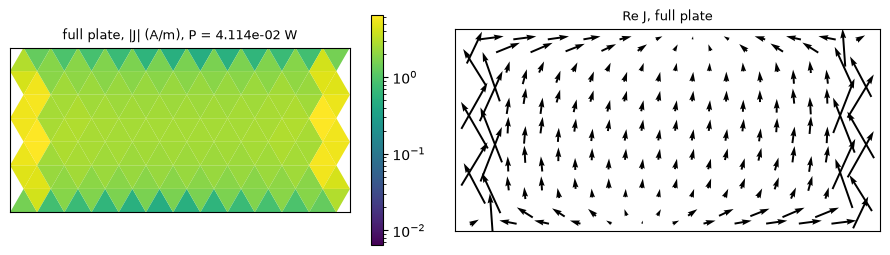

In [4]:
# mesh of the operators (exportOmWpatch21ka1.m): bf[n] = [T+, T-, edge node 1, edge node 2], 0 based
mesh = sio.loadmat(f"mesh_{matrixSet}.mat")
nodes, tria, bf = mesh["nodes"], mesh["triangles"], mesh["bf"]
edgeLen = np.linalg.norm(nodes[bf[:, 2]] - nodes[bf[:, 3]], axis=1)
e1, e2 = nodes[tria[:, 1]] - nodes[tria[:, 0]], nodes[tria[:, 2]] - nodes[tria[:, 0]]
triArea = 0.5*np.abs(e1[:, 0]*e2[:, 1] - e1[:, 1]*e2[:, 0])
triCent = nodes[tria].mean(axis=1)
freeNode = np.array([[np.setdiff1d(tria[t], bf[n, 2:])[0] for t in bf[n, :2]] for n in range(Ndes)]) # free vertices of T+, T-
print(f"{len(nodes)} nodes, {len(tria)} triangles, plate {np.ptp(nodes[:, 0])*1e3:.2f} x {np.ptp(nodes[:, 1])*1e3:.2f} mm, "
      f"Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error {np.max(np.abs(Ldiag/(5/(6*np.sqrt(3))*edgeLen**2) - 1)):.1e}")

def currentDensity(I):
    # RWG current density at the triangle centroids, J = I_n l_n rho / (2 A)
    J = np.zeros((len(tria), 2), dtype=complex)
    for s, sgn in [(0, 1), (1, -1)]:
        rho = sgn*(triCent[bf[:, s]] - nodes[freeNode[:, s]])
        np.add.at(J, bf[:, s], (I*edgeLen/(2*triArea[bf[:, s]]))[:, None]*rho)
    return J

def plotStructure(ax, keep, I, title=""):
    # metal triangles colored by |J| (log); removed RWG functions between metal triangles are slots (red), void triangles white
    metal = np.zeros(len(tria), dtype=bool)
    metal[bf[keep, :2].ravel()] = True
    J = np.linalg.norm(np.abs(currentDensity(I)), axis=1)
    pc = PolyCollection(nodes[tria[metal]], array=np.maximum(J[metal], 1e-3*J.max()), cmap='viridis',
                        norm=LogNorm(1e-3*J.max(), J.max()), edgecolors='none')
    ax.add_collection(pc)
    ax.add_collection(PolyCollection(nodes[tria[~metal]], facecolors='white', edgecolors='0.85', linewidths=0.3))
    slot = ~keep & metal[bf[:, 0]] & metal[bf[:, 1]]
    ax.add_collection(LineCollection(nodes[bf[slot, 2:]], colors='r', linewidths=1.5))
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return pc

def plotDensity(ax, d, title=""):
    # inferred density on the RWG edges
    lc = LineCollection(nodes[bf[:, 2:]], array=np.log10(np.maximum(d, 1e-6)), cmap='viridis', linewidths=2.5)
    lc.set_clim(-6, 0)
    ax.add_collection(lc)
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return lc

fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))
plt.colorbar(plotStructure(axes[0], np.ones(Ndes, dtype=bool), Ifull, f"full plate, |J| (A/m), P = {Pfull:.3e} W"), ax=axes[0])
axes[1].quiver(*triCent.T, *np.real(currentDensity(Ifull)).T, angles='xy', pivot='mid')
axes[1].set_aspect('equal'); axes[1].set_xticks([]); axes[1].set_yticks([]); axes[1].set_title("Re J, full plate", fontsize=9)
plt.tight_layout(); plt.show()

## QCQP with the stored energy constraint

The objective and the projector constraints are those of `maxScatVscatNoChol.ipynb`: $A_0 = -\tfrac12 W^H R_0 W$ with $W = Z_0^{-1}$, $I = -W x$, and
$\operatorname{Re}(-x^H A_1 P A_2 x + 2 x^H A_2^H P^H s_1) = 0$ with $A_1 = 1 + W^H Z_\mathrm{mat}^H$, $A_2 = W$, $s_1 = -\tfrac12 V$, which is
$\operatorname{Re}\sum_i p_i^* w_i = 0$, $w_i = I_i^*(V - Z_\mathrm{tot} I)_i$. The fixed $Q_W$ is a general constraint of dolphindes,
$\operatorname{Re}(-x^H A_2^H B A_2 x + 2 x^H A_2^H s_2 + c_2) = 0$, with
$$B = \frac{\omega W}{2 Q_0} - R_0, \qquad s_2 = 0, \qquad c_2 = 0, \qquad
-I^H B I = I^H R_0 I \left(1 - \frac{Q_W}{Q_0}\right) = 0 ,$$
scaled so that its residual is $2 P_\mathrm{rad}(1 - Q_W/Q_0)$ in watts, like the power conservation residuals.

**Inequality.** The Lagrangian contains $\mu\, I^H R_0 I (1 - Q_W/Q_0)$, nonnegative for $Q_W \leq Q_0$ if $\mu \geq 0$. A dual solution with
$\mu^\star \geq 0$ therefore also bounds all structures with $Q_W \leq Q_0$; this is the case below the $Q_W$ of the unconstrained optimum.

**Strong duality.** The dual is $D = \max_\lambda \min$ over the Lagrangian, $x^\star = A(\lambda)^{-1} S(\lambda)$. At an interior optimum
($L^\star = \operatorname{Sym} A(\lambda^\star) \succ 0$) the dual gradient, the vector of constraint residuals at $x^\star$, vanishes, so $x^\star$ is feasible,
$f_0(x^\star) = D$, and the duality gap is zero. At the PSD boundary ($L^\star$ singular, the *hard case*) the residuals need not vanish. With
the near-kernel $V$ of $L^\star$ orthogonal to $S$, the Lagrangian is constant on $x^\star + V\alpha$,
$$f_0(x) + \sum_k \lambda_k c_k(x) = D - (x - x^\star)^H L^\star (x - x^\star),$$
so any $x = x^\star + V\alpha$ with $c(x) = 0$ is a primal optimum with $f_0(x) = D$ (zero gap). The completion is found by least squares in
$\alpha$; a nonzero minimal residual means that no rank-one completion exists (a gap of the QCQP, or a non-converged dual).

In [5]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0) # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0
A1 = np.eye(Ndes) + WH @ Zmat.conj().T
A2 = W
s1 = -0.5 * Vinc

def VtoI(Vsca):
    return(-W @ Vsca)

def localViolation(I):
    # pointwise w_i = I_i^* (V - Ztot I)_i, zero for any structure made of enabled basis functions
    return(np.conj(I)*(Vinc - Ztot @ I))

def qConstraint(Q0):
    # Re(-I^H B I) = I^H R0 I (1 - Q_W/Q0) = 0, B = omW/(2 Q0) - R0 (general constraint, x = Vsca, A2 = W)
    return dict(B_j=[omW/(2*Q0) - R0], s_2j=[np.zeros(Ndes, dtype=complex)], c_2j=np.array([0.0]))

def buildQCQP(Plist, Q0=None):
    return DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, Plist, A2=A2, verbose=0, **({} if Q0 is None else qConstraint(Q0)))

def constraintRes(Q, x):
    # c_k(x) = Re(-x^H A_k x + 2 x^H F_k) + c_k for all constraints (W), zero for a feasible x
    res = np.real(-x.conj() @ Q._allA_at_v(x) + 2*x.conj() @ Q.Fs)
    res[Q.n_proj_constr:] += Q.c_2j
    return res

def completeKernel(Q, kerTol=1e-8, nStart=8, seed=0):
    # x = x* + V alpha on the near-kernel of L* (eig < kerTol max eig) with minimal constraint residual
    xs = Q.current_xstar
    lam, U = np.linalg.eigh(Msym(Q._get_total_A(Q.current_lags)))
    K = int(np.count_nonzero(lam < kerTol*lam[-1]))
    res0 = constraintRes(Q, xs)
    if K == 0:
        return xs, K, res0, res0
    V = U[:, :K]
    def fun(a):
        return constraintRes(Q, xs + V @ (a[:K] + 1j*a[K:]))/Q.current_dual
    def jac(a):
        # dc_k / d(Re, Im) alpha_j = 2 (Re, Im) v_j^H (F_k - A_k x)
        x = xs + V @ (a[:K] + 1j*a[K:])
        VG = V.conj().T @ (Q.Fs - Q._allA_at_v(x))
        return np.vstack([2*VG.real, 2*VG.imag]).T/Q.current_dual
    q = np.real(V[:, 0].conj() @ Q._allA_at_v(V[:, 0])) # c(x* + a v) = c(x*) - |a|^2 v^H A_k v for a single kernel vector
    scale = np.sqrt(np.abs(res0 @ q)/(q @ q))
    rng = np.random.default_rng(seed)
    a0 = [np.r_[scale, np.zeros(2*K - 1)]] + [scale*rng.standard_normal(2*K)/np.sqrt(K) for _ in range(nStart - 1)]
    sol = min((least_squares(fun, a, jac=jac, xtol=1e-15, ftol=1e-15, gtol=1e-15, max_nfev=200) for a in a0), key=lambda s: s.cost)
    x = xs + V @ (sol.x[:K] + 1j*sol.x[K:])
    return x, K, res0, constraintRes(Q, x)

def dualReport(name, Q, t=None):
    # bound, multiplier of the Q constraint, spectrum of L*, residuals at x* and after the kernel completion
    D = Q.current_dual
    lam = np.linalg.eigvalsh(Msym(Q._get_total_A(Q.current_lags)))
    x, K, res0, res1 = completeKernel(Q)
    I = VtoI(x)
    w = localViolation(I)
    mu = Q.current_lags[Q.n_proj_constr] if Q.n_gen_constr else np.nan
    gap = (D - evalObj(I))/D
    print(f"{name}: D {D:.6e} W, mu " + ("none" if np.isnan(mu) else f"{mu:+.3e}") + f", min eig L* / max {lam[0]/lam[-1]:.1e}, "
          f"kernel dim {K}, ||c||/D: x* {np.linalg.norm(res0)/D:.1e} -> completed {np.linalg.norm(res1)/D:.1e}, "
          f"(D - P(I))/D {gap:+.1e}, Q_W(I) {evalQW(I):.2f}, max|w_i| / |I^H V| {np.abs(w).max()/np.abs(I.conj() @ Vinc):.1e}"
          + ("" if t is None else f", {t:.1f}s"))
    return dict(D=D, mu=mu, lam=lam, K=K, x=x, res0=res0, res1=res1, gap=gap)

# check: the Q constraint residual is 2 Prad (1 - Q_W/Q0), zero for the full plate at its own Q_W
for Q0 in [evalQW(Ifull), 2*evalQW(Ifull)]:
    Qt = buildQCQP([sp.diags(np.ones(Ndes, dtype=complex))], Q0)
    print(f"Q0 {Q0:.3f}: Q residual of the full plate {constraintRes(Qt, -Z0 @ Ifull)[-1]:.6e} W, "
          f"2 Prad (1 - Q_W/Q0) = {2*Pfull*(1 - evalQW(Ifull)/Q0):.6e} W")

cond(Z0) = 6.327e+02
Q0 10.312: Q residual of the full plate 1.641229e-16 W, 2 Prad (1 - Q_W/Q0) = 0.000000e+00 W


Q0 20.624: Q residual of the full plate 4.114174e-02 W, 2 Prad (1 - Q_W/Q0) = 4.114174e-02 W


## Inference

As in `maxScatVscatNoChol.ipynb`: the relaxed density enters through the admittance form $Z_s L_{ii} I_i = d_i u_i$, the pointwise fits
(impedance and admittance form) project the dual current, and the Lagrangian solution fit minimizes
$J(d) = (x(d) - x^\star)^H L^\star (x(d) - x^\star)$ over $d \in [0, 1]^N$. The fit is nonconvex and depends on the start, so it is started from both
pointwise fits, $d = 0.5$, and the full plate, and the smallest $J$ is kept. $J$ is blind to the kernel of $L^\star$, so a small kernel makes the
target better defined. The relaxed design is rounded with thresholds $t \in [10^{-6}, 1)$ (logarithmic: the physical transition of the
admittance form for copper lies at small $d$) and the binary design with the largest scattered power is kept.

For a binary design all projector constraints hold, and the Lagrangian identity gives
$P = D - J - \mu\, I^H R_0 I\,(1 - Q_W/Q_0)$: the design misses the bound by $J$ and by the mismatch of its own $Q_W$ from $Q_0$.

In [6]:
dMin = 1e-6 # basis functions with d_i < dMin are removed in the realized structure
thsLog = np.logspace(-6, 0, 61)[:-1] # thresholds for binary rounding of d

def inferDimp(I):
    # impedance form: series impedance projected onto the passive ray, d = 1/(1 + t)
    nz = I != 0
    r = np.zeros(Ndes, dtype=complex)
    r[nz] = (Vinc - Ztot @ I)[nz]/I[nz] # inferred series impedance per basis function
    t = np.maximum(0, np.real(np.conj(Zs)*r)/(np.abs(Zs)**2*Ldiag))
    return np.where(nz, 1/(1 + t), 0.0)

def inferDadm(I):
    # admittance form: pointwise current fit of Zs Lii I_i = d_i u_i
    u = Vinc - Ztot @ I + Zs*Ldiag*I # driving voltage without the material self term
    b = u/(Zs*Ldiag) # current of a full material basis function driven by u
    return np.clip(np.real(np.conj(b)*I)/np.abs(b)**2, 0, 1)

def realizedCurrent(d):
    # (Ztot + diag(Zs Lii (1/d - 1))) I = V on the kept basis functions, I = 0 elsewhere
    keep = d >= dMin
    I = np.zeros(Ndes, dtype=complex)
    Zd = Ztot + np.diag(Zs*Ldiag*(1/np.maximum(d, dMin) - 1))
    I[keep] = np.linalg.solve(Zd[np.ix_(keep, keep)], Vinc[keep])
    return I

TX = -Z0 # x = TX I, the variable of the bound
Zoff = Ztot - Zs*np.diag(Ldiag) # system matrix without the material self terms

def solutionModel(d):
    # admittance form: (Zs diag(Lii) + diag(d) Z') I = diag(d) V
    M = Zs*np.diag(Ldiag) + d[:, None]*Zoff
    return M, np.linalg.solve(M, d*Vinc)

def lagFactor(Q):
    # C with C^H C = Sym A(lambda*), from the eigendecomposition (L* is nearly singular)
    lam, U = np.linalg.eigh(Msym(Q._get_total_A(Q.current_lags)))
    return np.sqrt(np.maximum(lam, 0))[:, None] * U.conj().T

def stackRI(M):
    return np.vstack([M.real, M.imag]) if M.ndim == 2 else np.concatenate([M.real, M.imag])

def lagDist(C, xs, d):
    # J(d) = ||C (x(d) - x*)||^2
    return np.linalg.norm(C @ (TX @ solutionModel(d)[1] - xs))**2

def fitSolutionLag(C, xs, d0):
    # argmin_{d in [0,1]^N} ||C (x(d) - x*)||^2
    CT = C @ TX
    Cx = C @ xs
    def fun(d):
        return stackRI(CT @ solutionModel(d)[1] - Cx)
    def jac(d):
        M, I = solutionModel(d)
        return stackRI((CT @ np.linalg.inv(M)) * (Vinc - Zoff @ I)[None, :]) # column j: T M^{-1} e_j [V - Z' I]_j
    sol = least_squares(fun, np.clip(d0, 1e-3, 1 - 1e-3), jac=jac, bounds=(0, 1), method='trf',
                        xtol=1e-12, ftol=1e-12, max_nfev=500)
    return sol.x

def bestBinary(d):
    # binary rounding over the thresholds, the design with the largest scattered power
    designs = [d > t for t in thsLog]
    currents = [realizedCurrent(k.astype(float)) for k in designs]
    Pb = np.array([evalObj(I) for I in currents])
    k = int(np.argmax(Pb))
    return dict(keep=designs[k], I=currents[k], P=Pb[k], QW=evalQW(currents[k]) if Pb[k] > 0 else np.nan,
                Q=evalQ(currents[k]) if Pb[k] > 0 else np.nan, th=thsLog[k])

def inferAll(Q, x):
    # pointwise fits of the (completed) dual current and the Lagrangian solution fit from four starts
    C = lagFactor(Q)
    I = VtoI(x)
    dPoint = {"impedance form": inferDimp(I), "admittance form": inferDadm(I)}
    starts = {**dPoint, "uniform 0.5": np.full(Ndes, 0.5), "full plate": np.ones(Ndes)}
    fits = {k: fitSolutionLag(C, Q.current_xstar, d0) for k, d0 in starts.items()}
    J = {k: lagDist(C, Q.current_xstar, d) for k, d in fits.items()}
    start = min(J, key=J.get)
    out = {form: dict(d=d, **bestBinary(d)) for form, d in dPoint.items()}
    out["Lagrangian fit"] = dict(d=fits[start], start=start, J=J[start], Prelax=evalObj(realizedCurrent(fits[start])),
                                 **bestBinary(fits[start]))
    return out

def lagIdentity(Q, I):
    # D - J - sum_k lambda_k c_k(x) and f0(x) for x = TX I, equal for any x
    e = TX @ I - Q.current_xstar
    J = np.real(e.conj() @ Msym(Q._get_total_A(Q.current_lags)) @ e)
    return Q.current_dual - J - Q.current_lags @ constraintRes(Q, TX @ I), evalObj(I)

# check: both pointwise forms recover the full plate exactly
for form, infer in [("impedance form", inferDimp), ("admittance form", inferDadm)]:
    d = infer(Ifull)
    print(f"full plate, {form}: max |d - 1| = {np.max(np.abs(d - 1)):.2e}, realized objective {evalObj(realizedCurrent(d)):.6e} W")

full plate, impedance form: max |d - 1| = 1.15e-09, realized objective 4.114174e-02 W
full plate, admittance form: max |d - 1| = 1.15e-09, realized objective 4.114174e-02 W


## Global bound and the Pareto front in $Q_W$

The global real and reactive power constraints, $p = \mathbf 1$ and $p = j\mathbf 1$, with and without the fixed $Q_W$. With only the two power
constraints the complex QCQP is strongly dual (Huang and Zhang, two constraints plus the linear terms); the third constraint is checked
numerically. The sweep runs from just above the smallest $Q_W$ of any current to beyond the $Q_W$ of the unconstrained optimum.

In [7]:
opt_params = OptimizationHyperparameters(opttol=1e-8,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=20,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

PlistGlob = [sp.diags(q*np.ones(Ndes, dtype=complex)) for q in [1, 1j]] # global real and reactive power
QCQP = buildQCQP(PlistGlob)
t1 = time.time()
QCQP.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0]), opt_params=opt_params)
glob = dualReport("global", QCQP, time.time() - t1)
QWglob = evalQW(VtoI(glob["x"]))
print(f"Q_W of the unconstrained optimum {QWglob:.1f}, Q {evalQ(VtoI(glob['x'])):.1f}; bound / full plate {glob['D']/Pfull:.0f}, "
      f"bound / resonant dipole {glob['D']/Pdip:.2f}")

Q0sweep = np.geomspace(1.15*QWmin, 2*QWglob, 30)
sweep = []
t1 = time.time()
for Q0 in Q0sweep:
    Qs = buildQCQP(PlistGlob, Q0)
    Qs.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0, 0.0]), opt_params=opt_params)
    with contextlib.redirect_stdout(io.StringIO()):
        sweep.append(dualReport(f"Q0 {Q0:.2f}", Qs))
    r = sweep[-1]
    print(f"Q0 {Q0:7.2f}: D {r['D']:.4e} W, mu {r['mu']:+.2e}, min eig L*/max {r['lam'][0]/r['lam'][-1]:.1e}, kernel {r['K']}, "
          f"||c||/D {np.linalg.norm(r['res0'])/r['D']:.1e} -> {np.linalg.norm(r['res1'])/r['D']:.1e}, "
          f"(D - P)/D {r['gap']:+.1e}, Q_W(I) {evalQW(VtoI(r['x'])):.2f}")
print(f"sweep: {time.time()-t1:.1f}s")
Dsweep = np.array([r["D"] for r in sweep])

global: D 1.847944e+01 W, mu none, min eig L* / max 8.7e-06, kernel dim 0, ||c||/D: x* 2.3e-04 -> completed 2.3e-04, (D - P(I))/D -2.4e-08, Q_W(I) 318.42, max|w_i| / |I^H V| 4.0e+01, 0.1s
Q_W of the unconstrained optimum 318.4, Q 318.5; bound / full plate 449, bound / resonant dipole 1.95


Q0    4.98: D 5.4728e-02 W, mu +3.47e+00, min eig L*/max 2.0e-10, kernel 1, ||c||/D 8.4e-01 -> 3.6e-08, (D - P)/D +1.8e-08, Q_W(I) 4.98


Q0    5.89: D 4.0384e-01 W, mu +6.25e+00, min eig L*/max 1.8e-11, kernel 1, ||c||/D 6.0e+00 -> 1.2e-11, (D - P)/D +2.0e-10, Q_W(I) 5.89


Q0    6.96: D 1.4590e+00 W, mu +2.43e+00, min eig L*/max 3.9e-11, kernel 1, ||c||/D 8.5e+00 -> 2.3e-10, (D - P)/D +9.0e-11, Q_W(I) 6.96


Q0    8.22: D 2.7537e+00 W, mu +1.52e+00, min eig L*/max 5.3e-11, kernel 1, ||c||/D 1.1e+01 -> 1.3e-10, (D - P)/D +2.6e-10, Q_W(I) 8.22


...

Q0  167.04: D 1.7850e+01 W, mu +4.70e-02, min eig L*/max 1.5e-05, kernel 0, ||c||/D 1.4e-04 -> 1.4e-04, (D - P)/D +5.4e-10, Q_W(I) 167.04
Q0  197.45: D 1.8108e+01 W, mu +3.85e-02, min eig L*/max 1.3e-05, kernel 0, ||c||/D 3.1e-04 -> 3.1e-04, (D - P)/D +1.5e-09, Q_W(I) 197.45


Q0  233.41: D 1.8311e+01 W, mu +2.77e-02, min eig L*/max 1.1e-05, kernel 0, ||c||/D 1.0e-04 -> 1.0e-04, (D - P)/D +1.4e-08, Q_W(I) 233.41
Q0  275.91: D 1.8441e+01 W, mu +1.41e-02, min eig L*/max 9.9e-06, kernel 0, ||c||/D 2.0e-04 -> 2.0e-04, (D - P)/D -5.5e-09, Q_W(I) 275.91


Q0  326.15: D 1.8478e+01 W, mu -2.62e-03, min eig L*/max 8.5e-06, kernel 0, ||c||/D 1.2e-05 -> 1.2e-05, (D - P)/D +4.5e-09, Q_W(I) 326.15
Q0  385.54: D 1.8401e+01 W, mu -2.32e-02, min eig L*/max 7.3e-06, kernel 0, ||c||/D 2.4e-04 -> 2.4e-04, (D - P)/D +9.8e-10, Q_W(I) 385.54


Q0  455.75: D 1.8185e+01 W, mu -4.83e-02, min eig L*/max 6.2e-06, kernel 0, ||c||/D 1.5e-04 -> 1.5e-04, (D - P)/D +2.8e-09, Q_W(I) 455.75
Q0  538.73: D 1.7805e+01 W, mu -7.89e-02, min eig L*/max 5.2e-06, kernel 0, ||c||/D 4.7e-04 -> 4.7e-04, (D - P)/D -5.7e-09, Q_W(I) 538.73


Q0  636.83: D 1.7238e+01 W, mu -1.16e-01, min eig L*/max 4.3e-06, kernel 0, ||c||/D 9.7e-04 -> 9.7e-04, (D - P)/D +1.6e-08, Q_W(I) 636.83
sweep: 9.1s


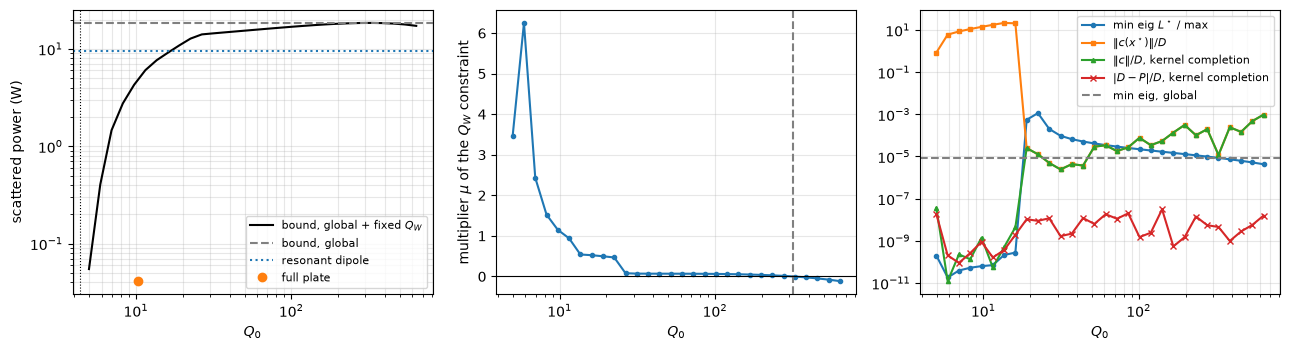

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axes[0]
ax.loglog(Q0sweep, Dsweep, 'k-', label=r'bound, global + fixed $Q_W$')
ax.axhline(glob["D"], ls='--', c='gray', label='bound, global')
ax.axhline(Pdip, ls=':', c='tab:blue', label='resonant dipole')
ax.plot(evalQW(Ifull), Pfull, 'o', c='tab:orange', label='full plate')
ax.axvline(QWmin, ls=':', c='k', lw=0.8)
ax.set_xlabel(r'$Q_0$'); ax.set_ylabel('scattered power (W)'); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
ax = axes[1]
ax.semilogx(Q0sweep, [r["mu"] for r in sweep], 'o-', ms=3)
ax.axvline(QWglob, ls='--', c='gray'); ax.axhline(0, c='k', lw=0.8)
ax.set_xlabel(r'$Q_0$'); ax.set_ylabel(r'multiplier $\mu$ of the $Q_W$ constraint'); ax.grid(True, alpha=0.3)
ax = axes[2]
ax.loglog(Q0sweep, [r["lam"][0]/r["lam"][-1] for r in sweep], 'o-', ms=3, label=r'min eig $L^\star$ / max')
ax.loglog(Q0sweep, [np.linalg.norm(r["res0"])/r["D"] for r in sweep], 's-', ms=3, label=r'$\|c(x^\star)\|/D$')
ax.loglog(Q0sweep, [max(np.linalg.norm(r["res1"])/r["D"], 1e-16) for r in sweep], '^-', ms=3, label=r'$\|c\|/D$, kernel completion')
ax.loglog(Q0sweep, [max(abs(r["gap"]), 1e-16) for r in sweep], 'x-', ms=4, label=r'$|D - P|/D$, kernel completion')
ax.axhline(glob["lam"][0]/glob["lam"][-1], ls='--', c='gray', label='min eig, global')
ax.set_xlabel(r'$Q_0$'); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## GCD and the full local bound at selected $Q_0$

`run_gcd` adds two diagonal projectors per iteration and keeps the general $Q_W$ constraint (its multiplier is carried along). The full local
problem uses all $2N$ pointwise constraints, $p = e_i$ and $p = j e_i$, plus the $Q_W$ constraint; the multipliers $\lambda_i = 1$ on the real power
constraints and $\mu = 0$ are dual feasible. A structure satisfies every projector constraint, so a feasible (completed) dual current of the
full local problem with zero pointwise violation would be a structure.

In [9]:
Q0sel = [None, 50, 25, 18, 12] # None: no Q_W constraint
Ngcd = 20 # number of GCD iterations

gcd = {}
for Q0 in Q0sel:
    Qg = buildQCQP(PlistGlob, Q0)
    Qg.solve_current_dual_problem(method='newton', init_lags=np.r_[1.0, 0.0, np.zeros(Qg.n_gen_constr)], opt_params=opt_params)
    glb = copy.deepcopy(Qg)
    gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd,
        max_gcd_iter_num=Ngcd,
        gcd_iter_period=Ngcd + 1, # no early termination
        opt_params=opt_params)
    t1 = time.time()
    with contextlib.redirect_stdout(io.StringIO()): # silence the per-iteration GCD output
        Qg.run_gcd(gcd_params)
    gcd[Q0] = dict(globQ=glb, Q=Qg, **dualReport(f"GCD {Ngcd}, Q0 {Q0}", Qg, time.time() - t1))

GCD 20, Q0 None: D 1.773461e+01 W, mu none, min eig L* / max 1.0e-13, kernel dim 1, ||c||/D: x* 5.7e-03 -> completed 5.3e-03, (D - P(I))/D +2.3e-05, Q_W(I) 258.66, max|w_i| / |I^H V| 4.7e+01, 23.8s


GCD 20, Q0 50: D 1.478258e+01 W, mu +6.818e-02, min eig L* / max 6.7e-12, kernel dim 1, ||c||/D: x* 3.5e-02 -> completed 3.3e-04, (D - P(I))/D +7.9e-05, Q_W(I) 50.00, max|w_i| / |I^H V| 4.6e+00, 18.3s


GCD 20, Q0 25: D 1.296413e+01 W, mu +1.958e-01, min eig L* / max 8.2e-12, kernel dim 2, ||c||/D: x* 3.2e-01 -> completed 9.6e-04, (D - P(I))/D +3.3e-03, Q_W(I) 25.00, max|w_i| / |I^H V| 2.0e+00, 35.8s


GCD 20, Q0 18: D 1.025796e+01 W, mu +4.956e-01, min eig L* / max 2.2e-10, kernel dim 1, ||c||/D: x* 8.5e-01 -> completed 6.6e-04, (D - P(I))/D -4.8e-02, Q_W(I) 18.00, max|w_i| / |I^H V| 1.2e+00, 37.1s


GCD 20, Q0 12: D 6.044246e+00 W, mu +9.231e-01, min eig L* / max 1.6e-11, kernel dim 2, ||c||/D: x* 3.7e-01 -> completed 3.7e-04, (D - P(I))/D +8.5e-03, Q_W(I) 12.00, max|w_i| / |I^H V| 4.4e-01, 36.0s


In [10]:
Pdiags = np.column_stack([np.eye(Ndes, dtype=complex), 1j*np.eye(Ndes, dtype=complex)])
PlistAll = [sp.diags(Pdiags[:, i]) for i in range(Pdiags.shape[1])]
print(f"number of projector constraints: {len(PlistAll)}")

full_opt_params = OptimizationHyperparameters(opttol=1e-10,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=30,
    penalty_ratio=1e-3,
    penalty_reduction=0.01,
    break_iter_period=5,
    verbose=0)

loc = {}
for Q0 in Q0sel:
    Ql = buildQCQP(PlistAll, Q0)
    lags_init = np.zeros(2*Ndes + Ql.n_gen_constr)
    lags_init[:Ndes] = 1.0 # lambda_i = 1 on all real power constraints
    t1 = time.time()
    Ql.solve_current_dual_problem(method='newton', init_lags=lags_init, opt_params=full_opt_params)
    loc[Q0] = dict(Q=Ql, **dualReport(f"full local, Q0 {Q0}", Ql, time.time() - t1))

number of projector constraints: 466


full local, Q0 None: D 1.748000e+01 W, mu none, min eig L* / max 6.9e-16, kernel dim 8, ||c||/D: x* 6.5e+01 -> completed 6.1e+01, (D - P(I))/D +5.9e-05, Q_W(I) 216.74, max|w_i| / |I^H V| 1.0e+01, 36.2s


full local, Q0 50: D 1.466656e+01 W, mu +7.398e-02, min eig L* / max 3.7e-16, kernel dim 4, ||c||/D: x* 7.0e+00 -> completed 6.8e+00, (D - P(I))/D +1.6e-05, Q_W(I) 43.51, max|w_i| / |I^H V| 7.2e-01, 53.5s


full local, Q0 25: D 1.285618e+01 W, mu +1.784e-01, min eig L* / max 1.9e-14, kernel dim 3, ||c||/D: x* 7.3e+00 -> completed 6.9e+00, (D - P(I))/D -1.4e-05, Q_W(I) 20.59, max|w_i| / |I^H V| 9.0e-01, 62.5s


full local, Q0 18: D 1.023843e+01 W, mu +4.967e-01, min eig L* / max 8.5e-11, kernel dim 1, ||c||/D: x* 3.4e+00 -> completed 2.8e+00, (D - P(I))/D +1.1e-02, Q_W(I) 10.17, max|w_i| / |I^H V| 2.2e-01, 53.8s


full local, Q0 12: D 5.976824e+00 W, mu +9.287e-01, min eig L* / max 5.8e-14, kernel dim 4, ||c||/D: x* 2.4e+00 -> completed 1.8e+00, (D - P(I))/D +2.3e-01, Q_W(I) 8.79, max|w_i| / |I^H V| 1.6e-01, 83.3s


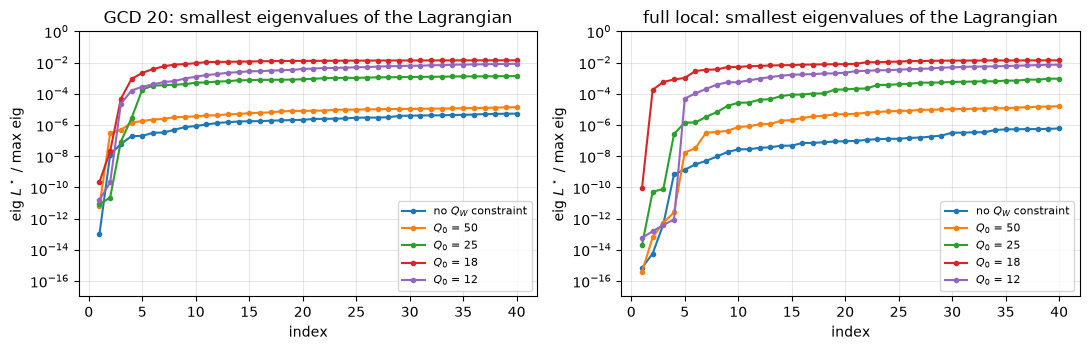

   Q0 |    global       GCD     local (W) | kernel GCD/local | #eig < 1e-6 max | max|w|/|IV| GCD/local | (D - P)/D GCD/local (completed)
 None |   18.4794   17.7346   17.4800     |      1 /   8     |     10 /  52    | 4.7e+01 / 1.0e+01   | +2.3e-05 / +5.9e-05
   50 |   15.3803   14.7826   14.6666     |      1 /   4     |      3 /  11    | 4.6e+00 / 7.2e-01   | +7.9e-05 / +1.6e-05
   25 |   13.9330   12.9641   12.8562     |      2 /   3     |      3 /   4    | 2.0e+00 / 9.0e-01   | +3.3e-03 / -1.4e-05
   18 |   10.2887   10.2580   10.2384     |      1 /   1     |      2 /   1    | 1.2e+00 / 2.2e-01   | -4.8e-02 / +1.1e-02
   12 |    6.5468    6.0442    5.9768     |      2 /   4     |      2 /   4    | 4.4e-01 / 1.6e-01   | +8.5e-03 / +2.3e-01


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, res, title in [(axes[0], gcd, f'GCD {Ngcd}'), (axes[1], loc, 'full local')]:
    for Q0, r in res.items():
        ax.semilogy(np.arange(1, 41), r["lam"][:40]/r["lam"][-1], '.-', label='no $Q_W$ constraint' if Q0 is None else f'$Q_0$ = {Q0}')
    ax.set_xlabel('index'); ax.set_ylabel(r'eig $L^\star$ / max eig'); ax.set_title(f'{title}: smallest eigenvalues of the Lagrangian')
    ax.set_ylim(1e-17, 1); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'Q0':>5s} | {'global':>9s} {'GCD':>9s} {'local':>9s} (W) | kernel GCD/local | #eig < 1e-6 max | "
      f"max|w|/|IV| GCD/local | (D - P)/D GCD/local (completed)")
for Q0 in Q0sel:
    g, l = gcd[Q0], loc[Q0]
    wv = [np.abs(localViolation(VtoI(r["x"]))).max()/np.abs(VtoI(r["x"]).conj() @ Vinc) for r in (g, l)]
    ns = [np.count_nonzero(r["lam"] < 1e-6*r["lam"][-1]) for r in (g, l)]
    print(f"{str(Q0):>5s} | {g['globQ'].current_dual:9.4f} {g['D']:9.4f} {l['D']:9.4f}     | {g['K']:6d} / {l['K']:3d}     | "
          f"{ns[0]:6d} / {ns[1]:3d}    | {wv[0]:.1e} / {wv[1]:.1e}   | {g['gap']:+.1e} / {l['gap']:+.1e}")

## Direct inference

Every dual solution (global, GCD, full local) at every $Q_0$ is turned into a structure. The table lists the best binary design of each
inference, its $Q_W$ and tuned $Q$, and for the Lagrangian fit the relative misfit $J/D$ and the relaxed design power. The realized
structures are then placed in the $(Q_W, P)$ plane; the bound at fixed $Q_W$ applies to every structure with that $Q_W$.

In [12]:
inf = {}
t1 = time.time()
for Q0 in Q0sel:
    for kind, Q, x in [("global", gcd[Q0]["globQ"], None), (f"GCD {Ngcd}", gcd[Q0]["Q"], gcd[Q0]["x"]), ("full local", loc[Q0]["Q"], loc[Q0]["x"])]:
        if x is None:
            x = completeKernel(Q)[0]
        inf[(kind, Q0)] = dict(inferAll(Q, x), D=Q.current_dual, x=x)
print(f"inference: {time.time()-t1:.1f}s")

print(f"{'dual':>10s} {'Q0':>5s} {'D (W)':>8s} | {'impedance form':>22s} | {'admittance form':>22s} | Lagrangian fit: J/D, start, relaxed P, binary P (Q_W, Q)")
for (kind, Q0), r in inf.items():
    pw = [f"{r[f]['P']:.2e} ({r[f]['QW']:5.1f})" for f in ["impedance form", "admittance form"]]
    lf = r["Lagrangian fit"]
    print(f"{kind:>10s} {str(Q0):>5s} {r['D']:8.3f} | {pw[0]:>22s} | {pw[1]:>22s} | {lf['J']/r['D']:.2f}, {lf['start']:15s}, "
          f"{lf['Prelax']:.2e}, {lf['P']:.3e} W ({lf['QW']:.1f}, {lf['Q']:.1f})")

# check of the Lagrangian identity for the best design: P = D - J - lambda . c(x)
kind, Q0 = max(inf, key=lambda k: inf[k]["Lagrangian fit"]["P"])
Qbest = {"global": gcd[Q0]["globQ"], f"GCD {Ngcd}": gcd[Q0]["Q"], "full local": loc[Q0]["Q"]}[kind]
lhs, rhs = lagIdentity(Qbest, inf[(kind, Q0)]["Lagrangian fit"]["I"])
print(f"best design from {kind}, Q0 {Q0}: D - J - lambda.c = {lhs:.6e} W, P = {rhs:.6e} W")

inference: 198.0s
      dual    Q0    D (W) |         impedance form |        admittance form | Lagrangian fit: J/D, start, relaxed P, binary P (Q_W, Q)
    global  None   18.479 |       6.21e-02 ( 14.0) |       6.47e-02 (  8.6) | 0.57, full plate     , 5.64e+00, 7.232e+00 W (18.6, 18.8)
    GCD 20  None   17.735 |       4.14e-02 ( 10.3) |       1.22e-03 ( 49.9) | 0.54, uniform 0.5    , 6.51e+00, 7.849e+00 W (20.1, 20.2)
full local  None   17.480 |       4.89e-02 ( 10.9) |       7.61e-03 ( 25.0) | 0.53, full plate     , 5.93e+00, 7.813e+00 W (20.4, 20.6)
    global    50   15.380 |       5.59e-02 ( 11.7) |       1.15e-02 ( 20.9) | 0.42, full plate     , 6.19e+00, 7.749e+00 W (19.2, 19.4)
    GCD 20    50   14.783 |       6.81e-02 ( 16.8) |       1.67e-03 ( 44.5) | 0.39, full plate     , 6.82e+00, 8.384e+00 W (21.0, 21.1)
full local    50   14.667 |       5.17e-02 ( 12.1) |       6.34e-03 ( 27.4) | 0.37, full plate     , 7.77e+00, 8.557e+00 W (21.5, 21.6)
    global    25   13.933 |    

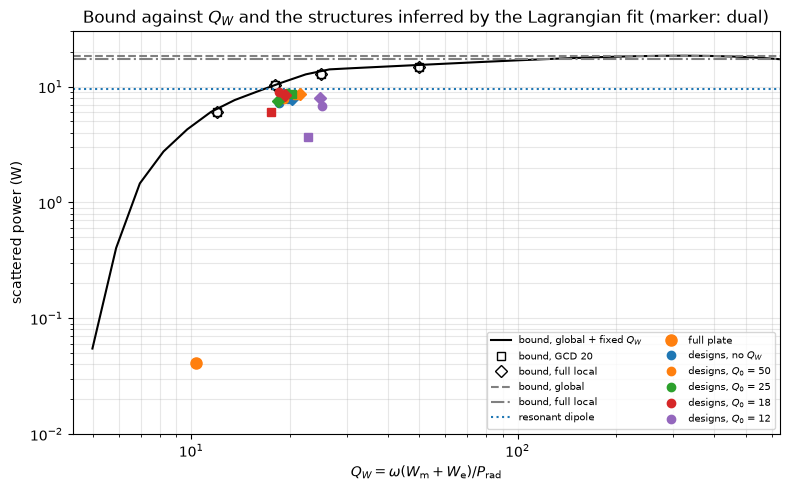

    global  None: design P 7.232 W at Q_W 18.6: 0.39 of its dual bound, 0.68 of the global bound at its own Q_W (10.63 W)
    GCD 20  None: design P 7.849 W at Q_W 20.1: 0.44 of its dual bound, 0.68 of the global bound at its own Q_W (11.48 W)
full local  None: design P 7.813 W at Q_W 20.4: 0.45 of its dual bound, 0.67 of the global bound at its own Q_W (11.64 W)
    global    50: design P 7.749 W at Q_W 19.2: 0.50 of its dual bound, 0.70 of the global bound at its own Q_W (10.99 W)
    GCD 20    50: design P 8.384 W at Q_W 21.0: 0.57 of its dual bound, 0.70 of the global bound at its own Q_W (12.02 W)
full local    50: design P 8.557 W at Q_W 21.5: 0.58 of its dual bound, 0.70 of the global bound at its own Q_W (12.28 W)
    global    25: design P 8.837 W at Q_W 19.6: 0.63 of its dual bound, 0.79 of the global bound at its own Q_W (11.21 W)
    GCD 20    25: design P 8.626 W at Q_W 20.4: 0.67 of its dual bound, 0.74 of the global bound at its own Q_W (11.65 W)
full local    25: design

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(Q0sweep, Dsweep, 'k-', label=r'bound, global + fixed $Q_W$')
for kind, mk in [(f"GCD {Ngcd}", 's'), ("full local", 'D')]:
    res = gcd if kind != "full local" else loc
    ax.plot([q for q in Q0sel if q is not None], [res[q]["D"] for q in Q0sel if q is not None], mk, mfc='none', c='k', label=f'bound, {kind}')
ax.axhline(glob["D"], ls='--', c='gray', label='bound, global')
ax.axhline(loc[None]["D"], ls='-.', c='gray', label='bound, full local')
ax.axhline(Pdip, ls=':', c='tab:blue', label='resonant dipole')
ax.plot(evalQW(Ifull), Pfull, 'o', c='tab:orange', ms=8, label='full plate')
colors = {Q0: f'C{k}' for k, Q0 in enumerate(Q0sel)}
markers = {"global": 'o', f"GCD {Ngcd}": 's', "full local": 'D'}
for (kind, Q0), r in inf.items():
    lf = r["Lagrangian fit"]
    if lf["P"] > 0:
        ax.plot(lf["QW"], lf["P"], markers[kind], c=colors[Q0], ms=6)
for Q0 in Q0sel:
    ax.plot([], [], 'o', c=colors[Q0], label='designs, no $Q_W$' if Q0 is None else f'designs, $Q_0$ = {Q0}')
ax.set_xlabel(r'$Q_W = \omega(W_\mathrm{m} + W_\mathrm{e}) / P_\mathrm{rad}$'); ax.set_ylabel('scattered power (W)')
ax.set_xlim(QWmin, 2*QWglob); ax.set_ylim(1e-2, 30)
ax.legend(fontsize=7, ncol=2); ax.grid(True, which='both', alpha=0.3)
ax.set_title('Bound against $Q_W$ and the structures inferred by the Lagrangian fit (marker: dual)')
plt.tight_layout(); plt.show()

DofQ = lambda q: np.interp(np.log(q), np.log(Q0sweep), Dsweep)
for (kind, Q0), r in inf.items():
    lf = r["Lagrangian fit"]
    if lf["P"] > 0:
        print(f"{kind:>10s} {str(Q0):>5s}: design P {lf['P']:.3f} W at Q_W {lf['QW']:.1f}: {lf['P']/r['D']:.2f} of its dual bound, "
              f"{lf['P']/DofQ(lf['QW']):.2f} of the global bound at its own Q_W ({DofQ(lf['QW']):.2f} W)")

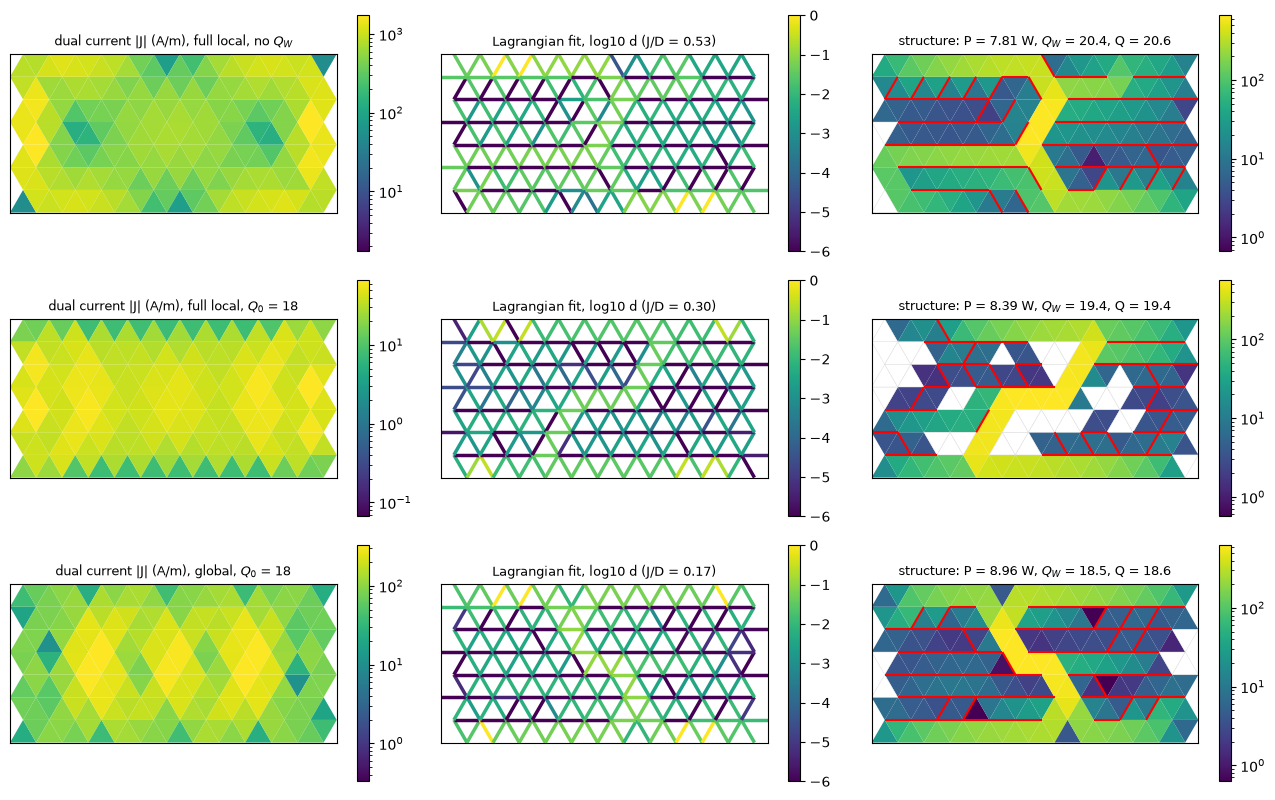

In [14]:
bestQ = max((k for k in inf if k[1] is not None and k != ("full local", 18)), key=lambda k: inf[k]["Lagrangian fit"]["P"])
show = [("full local", None), ("full local", 18), bestQ] # no Q_W constraint, Q0 = 18, best design of the remaining Q_W-constrained duals
fig, axes = plt.subplots(len(show), 3, figsize=(13, 2.7*len(show)))
for row, key in zip(axes, show):
    kind, Q0 = key
    lf = inf[key]["Lagrangian fit"]
    name = f"{kind}, " + ("no $Q_W$" if Q0 is None else f"$Q_0$ = {Q0}")
    plt.colorbar(plotStructure(row[0], np.ones(Ndes, dtype=bool), VtoI(inf[key]["x"]), f"dual current |J| (A/m), {name}"), ax=row[0])
    plt.colorbar(plotDensity(row[1], lf["d"], f"Lagrangian fit, log10 d (J/D = {lf['J']/inf[key]['D']:.2f})"), ax=row[1])
    plt.colorbar(plotStructure(row[2], lf["keep"], lf["I"],
                               f"structure: P = {lf['P']:.2f} W, $Q_W$ = {lf['QW']:.1f}, Q = {lf['Q']:.1f}"), ax=row[2])
plt.tight_layout(); plt.show()

## Conclusions

**Bound.** The stored energy turns the single scattering bound into a Pareto front in $Q_W$. The bound rises steeply from the smallest $Q_W$ of
any current on the plate (4.33) and bends at $Q_W \approx 20$–$26$ (the multiplier $\mu$ drops from 0.47 to 0.08), where it is 11–14 W,
1.1–1.5 times the lossless resonant dipole (9.49 W). The rest of the unconstrained bound, 18.48 W $\approx 2\times$ the dipole (a second resonant
channel), needs $Q_W \approx 320$. Since $\mu > 0$ below $Q_W \approx 318$, the front also bounds every structure with $Q_W \leq Q_0$. The pointwise
constraints tighten the bound by only 0.5–9 % (GCD 20, full local). At copper, the stored energy is what makes the bound informative: the
inferred structures ($Q_W$ 17.5–25) reach 0.6–0.84 of the fixed-$Q_W$ bound at their own $Q_W$ ($Q_0 \geq 18$), against 0.33–0.48 of the
unconstrained bound.

**Strong duality.** With the global constraints, the fixed-$Q_W$ QCQP has zero duality gap at every $Q_0$. For $Q_0 \geq 19$ the optimum is
interior, $|D - P|/D < 4\cdot 10^{-8}$. For $Q_0 \leq 16$ it is the hard case: the kernel is one-dimensional and its rank-one completion is
feasible to $4\cdot 10^{-8}$ or better. The smallest eigenvalue of $L^\star$ grows by up to two orders ($1.1\cdot 10^{-3}$ of the largest at $Q_0 = 22$, against
$8.7\cdot 10^{-6}$ without the constraint). With the pointwise constraints the dual stays on the PSD boundary at copper conductivity:
- the $Q_W$ constraint opens a spectral gap in $L^\star$: 52 eigenvalues below $10^{-6}$ of the largest without it, 1–4 for $Q_0 \leq 25$, and
  then a jump to $10^{-4}$–$10^{-3}$;
- the pointwise violation of the dual current drops by one to two orders: full local $\max|w_i|/|I^H V|$ goes from 10 to 0.16–0.9, GCD from 47 to 0.4–4.6;
- there is still no rank-one completion of the full local dual ($\|c\|/D$ stays of order one), so the full local problem is **not** strongly dual;
- GCD 20 is close to strongly dual with and without $Q_W$: after completion $\|c\|/D$ is $5\cdot 10^{-3}$ without the constraint and
  $3\cdot 10^{-4}$–$10^{-3}$ with it, with a gap of at most 5 %.

**Inference.** The pointwise (direct) inference fails without the constraint: at most 0.07 W, against 0.041 W for the full plate. It starts
to work at low $Q_0$, where the dual current is closest to a structure: the impedance form gives 3.5 W from the global dual at $Q_0 = 12$ and
0.7 W from GCD. The Lagrangian solution fit finds resonant bent-strip structures of 6–9 W (150–220 times the full plate) from every dual except GCD at
$Q_0 = 12$ (3.7 W). The $Q_W$ constraint lowers its misfit $J/D$ from 0.53–0.57 to 0.17–0.45 and raises the designs from 0.39–0.45 to 0.50–0.87 of their own dual bound ($Q_0 \geq 18$).
The best design is 8.96 W at $Q_W = 18.5$, from the global dual at $Q_0 = 18$; this is 0.84 of the bound at its $Q_W$ and 0.94 of the resonant
dipole.

The realized $Q_W$ does not follow $Q_0$ below about 18: $Q_0 = 12$ yields $Q_W \approx 23$–$25$. This mesh does not seem to admit self-resonant
structures with lower $Q_W$ at $ka = 1$. Such designs violate the fixed $Q_W$, which is why they can exceed their own dual bound. The best
designs are similar with and without the constraint (individual values vary by about 1 W between runs, from GCD and the nonconvex fit). The
constraint therefore improves the inference target and the certificate more than the best structure found.